

This notebook shows a simple example of statistical aggregations over the entire sky catalogue. Visualisation employs the HEALPixel pixelisation encoded in the Gaia source identifier.


In [ ]:
# Do the imports
from dask.distributed import Client
import dask.dataframe as dd
import seaborn as sns
import time
import dask
import numpy as np
import healpy as hp
import matplotlib.pyplot as plot
import math
from pathlib import Path
import os

# Set up the client
c = Client('tcp://simple-scheduler.dask-operator.svc.cluster.local:8786')
print(c)

<Client: 'tcp://192.168.63.173:8786' processes=10 threads=60, memory=250.00 GiB>


/usr/local/lib/python3.10/site-packages/distributed/client.py:1612: VersionMismatchWarning: Mismatched versions found

+---------+-----------------+-----------------+-----------------+
| Package | Client          | Scheduler       | Workers         |
+---------+-----------------+-----------------+-----------------+
| lz4     | 4.4.4           | 4.3.3           | 4.3.3           |
| numpy   | 2.2.6           | 2.2.2           | 2.2.2           |
| python  | 3.10.16.final.0 | 3.10.12.final.0 | 3.10.12.final.0 |
| toolz   | 1.0.0           | 0.12.0          | 0.12.0          |
| tornado | 6.4.1           | 6.4.2           | 6.4.2           |
+---------+-----------------+-----------------+-----------------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


In [ ]:
healpix_level = 6
nside = int(math.pow(2, healpix_level))
powers_of_2 = 35 + (12 - healpix_level)*2
divisor = int(math.pow(2, powers_of_2))

ddf = dd.read_parquet(Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath('GDR3_GAIA_SOURCE/'), columns=['source_id', 'pmra', 'pmdec'])

In [ ]:
_starttime = time.time()

# This is using the dataframe approach not the SparkSQL approach
ddf["hpx_id"] = np.floor(ddf.source_id / divisor)

result_df = ddf.groupby("hpx_id").agg({
    "hpx_id": "count", # n
    "pmra": "mean", # avg_pmra
    "pmdec": "mean", # avg_pmdec
})

result_df = result_df.rename(columns={
    "hpx_id": "n",
    "pmra": "avg_pmra",
    "pmdec": "avg_pmdec"
})

results = [result_df, ]
r = result_df.compute()

/usr/local/lib/python3.10/site-packages/healpy/visufunc.py:200: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  f = pylab.figure(fig, figsize=(8.5, 5.4))


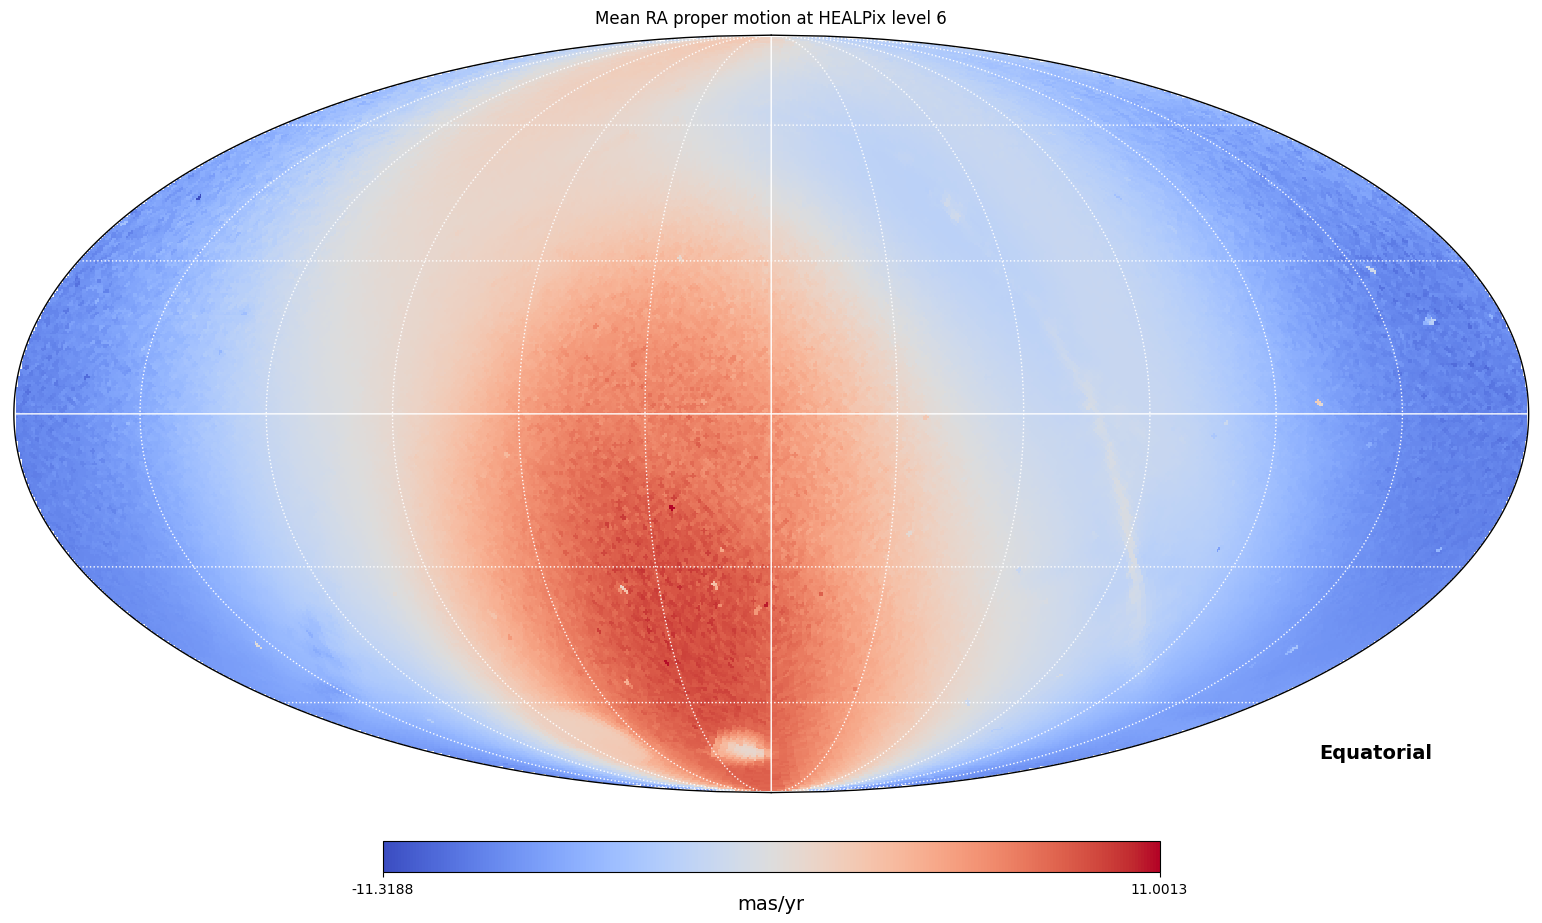

In [4]:
plot.figure(1, figsize = (16.18, 10.0))

# healpy constants appropriate to the HEALPix indexing encoded in Gaia source IDs
npix = hp.nside2npix(nside)

# do the visualisation
array_data = np.empty(npix)

for i, v in r['avg_pmra'].items():
    array_data[int(i)] = v
    
hp.mollview(array_data, fig = 1, coord='C', unit='mas/yr', nest=True, title='Mean RA proper motion at HEALPix level %d'%(healpix_level), cmap='coolwarm')
hp.graticule(coord='C', color='white')

/usr/local/lib/python3.10/site-packages/healpy/visufunc.py:200: UserWarning: Ignoring specified arguments in this call because figure with num: 2 already exists
  f = pylab.figure(fig, figsize=(8.5, 5.4))


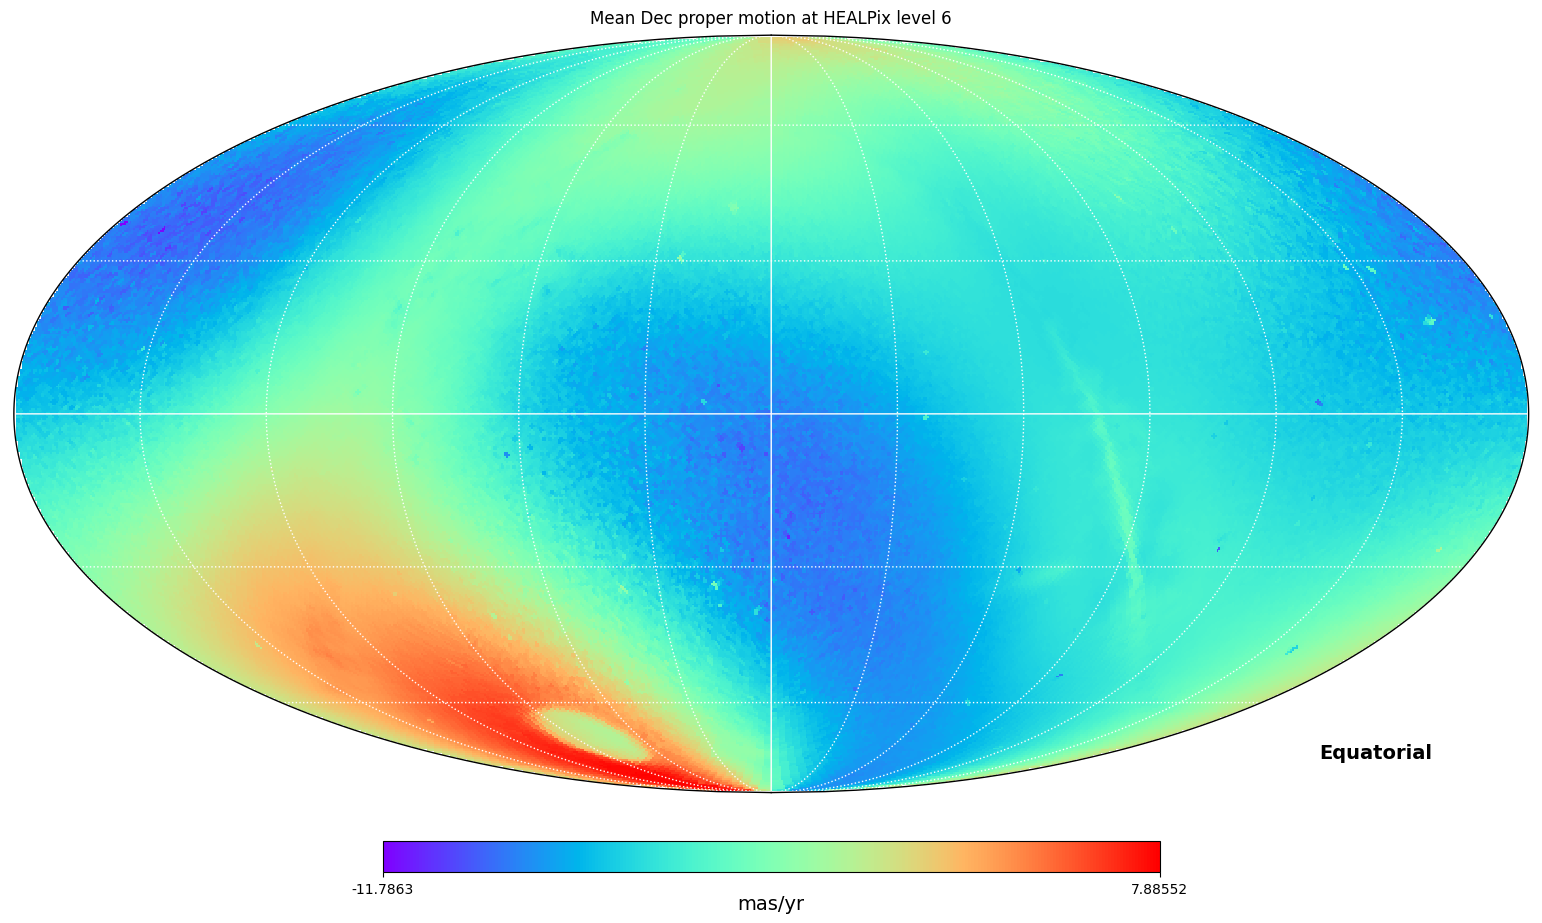

In [5]:
plot.figure(2, figsize = (16.18, 10.0))

array_data = np.empty(npix)

for i, v in r['avg_pmdec'].items():
    array_data[int(i)] = v
    
hp.mollview(array_data, fig=2, coord='C', unit='mas/yr', nest=True, title='Mean Dec proper motion at HEALPix level %d'%(healpix_level), cmap='rainbow')
hp.graticule(coord='C', color='white')